# Simulation examples

This notebook shows the current simulator API in two settings:

- one episode, step by step
- many episodes, with density mean and standard deviation


## Imports


In [3]:
import sys
from pathlib import Path

import igraph as ig
import matplotlib.pyplot as plt
import numpy as np

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")

from network_creation.core.agent import Agent
from network_creation.core.environment import Environment
from network_creation.core.graph import create_empty_graph
from network_creation.core.model import ActorScheduler
from network_creation.core.observability import ObservationSampling
from network_creation.core.simulator import Simulator
from network_creation.observers.grimoire import OBSERVER_GRIMOIRE
from network_creation.plotting.episode_series import plot_episode_series_observer
from network_creation.plotting.graph_history import (
    build_circle_layout,
    plot_graph_history,
)
from network_creation.policies.random import RandomPolicy
from network_creation.policies.best_response import BestResponsePolicy

ActionPrintObserver = OBSERVER_GRIMOIRE["action_print"]
DensityObserver = OBSERVER_GRIMOIRE["density"]
StateHistoryObserver = OBSERVER_GRIMOIRE["state_history"]
NormalizedWelfareObserver = OBSERVER_GRIMOIRE["normalized_welfare"]

## Single episode


In [4]:
initial_graph_adj = np.array(
    [
        [0, 1, 0, 0, 0],
        [0, 0, 1, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0],
    ],
    dtype=np.int8,
)
init_graph = ig.Graph.Adjacency(initial_graph_adj.tolist(), mode=ig.ADJ_DIRECTED)
fixed_layout = build_circle_layout(n_nodes=initial_graph_adj.shape[0])

env = Environment(graph=init_graph, seed=11)
fixed_layout = build_circle_layout(n_nodes=initial_graph_adj.shape[0])

agents = tuple(
    Agent(
        id=node_id,
        visibility_fraction=2 / initial_graph_adj.shape[0],
        policy=BestResponsePolicy(
            n_nodes=initial_graph_adj.shape[0],
            seed=11 + node_id,
            benefit_to_cost_ratio=0.5,
            distance_discount=0.9,
            temperature=0.2,
            bridge_value=0.0,
            inertia_term=0.0,
        ),
        seed=42 + node_id,
    )
    for node_id in range(initial_graph_adj.shape[0])
)

max_steps = 10
simulator_seed = 301
actor_scheduler = ActorScheduler(n_agents=initial_graph_adj.shape[0], fraction=1 / initial_graph_adj.shape[0], seed=simulator_seed)

action_printer = ActionPrintObserver(
    observation_sampling=ObservationSampling.periodic(1), print_empty_steps=False
)
state_history_observer = StateHistoryObserver(
    observation_sampling=ObservationSampling.periodic(1), keep_runs=False
)

In [5]:
simulator = Simulator(
    env=env,
    agents=agents,
    actor_scheduler=actor_scheduler,
    max_steps=max_steps,
    rng=np.random.default_rng(simulator_seed),
    observers=(action_printer, state_history_observer),
)

simulator.run(n_episodes=1, reset_observers=False)


step 1
  1: ADD->0 (value={value=-0.05})

step 2
  2: ADD->1 (value={value=-0.11})

step 3
  0: PASS (value={value=0.06})

step 4
  1: BRIDGE->4 (value={value=0.11})

step 5
  2: DELETE->1 (value={value=0.11})

step 6
  1: ADD->3 (value={value=0.01})

step 7
  1: PASS (value={value=0.11})

step 8
  4: ADD->3 (value={value=-0.11})

step 9
  3: ADD->2 (value={value=0.0})

step 10
  4: ADD->1 (value={value=0.0})


### Directed graph after each sampled step


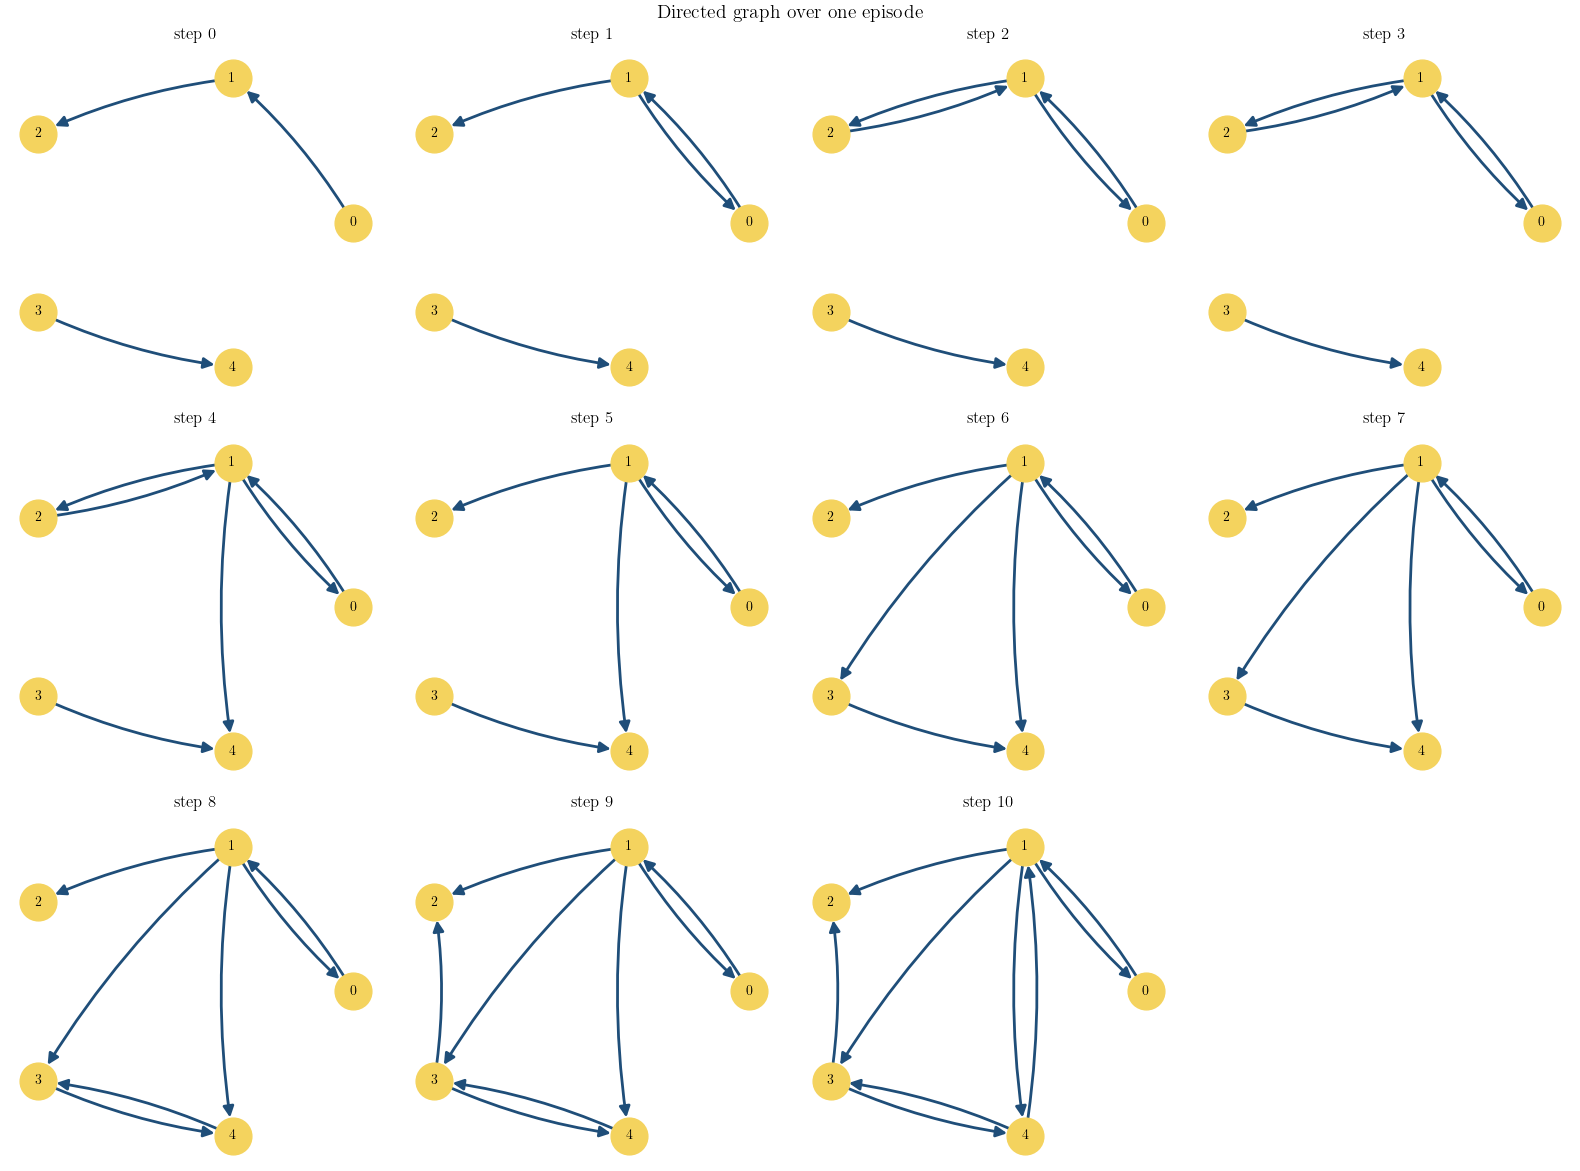

In [6]:
plot_graph_history(
    steps=state_history_observer.steps,
    graphs=state_history_observer.graphs,
    layout=fixed_layout,
    figure_title="Directed graph over one episode",
    max_cols=4,
)
plt.show()

## Multiple episodes

The simulator now derives a fresh seed for each agent at each episode.
That keeps repeated runs reproducible while avoiding identical random episodes.


In [7]:
n_agents = 10
multi_env = Environment(graph=create_empty_graph(n_agents=n_agents), seed=101)
multi_agents = tuple(
    Agent(
        id=node_id,
        visibility_fraction=n_agents / n_agents,
        policy=BestResponsePolicy(
            n_nodes=n_agents,
            seed=11 + node_id,
            benefit_to_cost_ratio=0.5,
            distance_discount=0.9,
            temperature=0.001,
            bridge_value=0.0,
            inertia_term=0.0,
        ),
        seed=500 + node_id,
    )
    for node_id in range(multi_env.state.graph.vcount())
)
multi_density_observer = NormalizedWelfareObserver(
    observation_sampling=ObservationSampling.periodic(1),
    aggregations=("mean", "std", "runs"),
    benefit_to_cost_ratio=0.5,
    distance_discount=0.9,
)
state_history_observer = StateHistoryObserver(
    observation_sampling=ObservationSampling.periodic(1), keep_runs=True
)

multi_simulator = Simulator(
    env=multi_env,
    agents=multi_agents,
    actor_scheduler=ActorScheduler(n_agents=len(multi_agents), fraction=1 / len(multi_agents), seed=41),
    max_steps=360*10,
    rng=np.random.default_rng(41),
    observers=(multi_density_observer, state_history_observer),
)

multi_simulator.run(n_episodes=16, reset_observers=True)
multi_density_result = multi_density_observer.get()
state_history_result = state_history_observer.get()

multi_density_result.n_episodes, tuple(multi_density_result.outputs)

(16, ('mean', 'std', 'runs'))

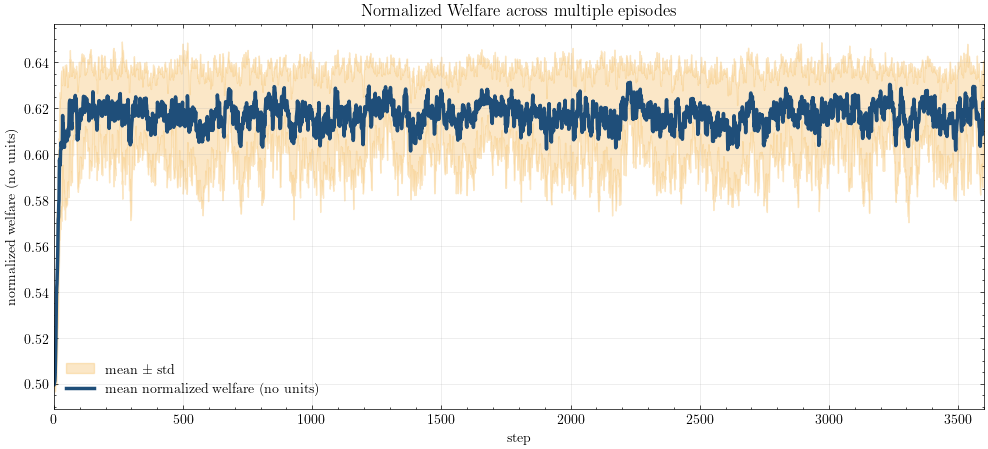

In [8]:
figure, axis = plt.subplots(figsize=(12, 5))
plot_episode_series_observer(observer=multi_density_observer, ax=axis)
plt.show()

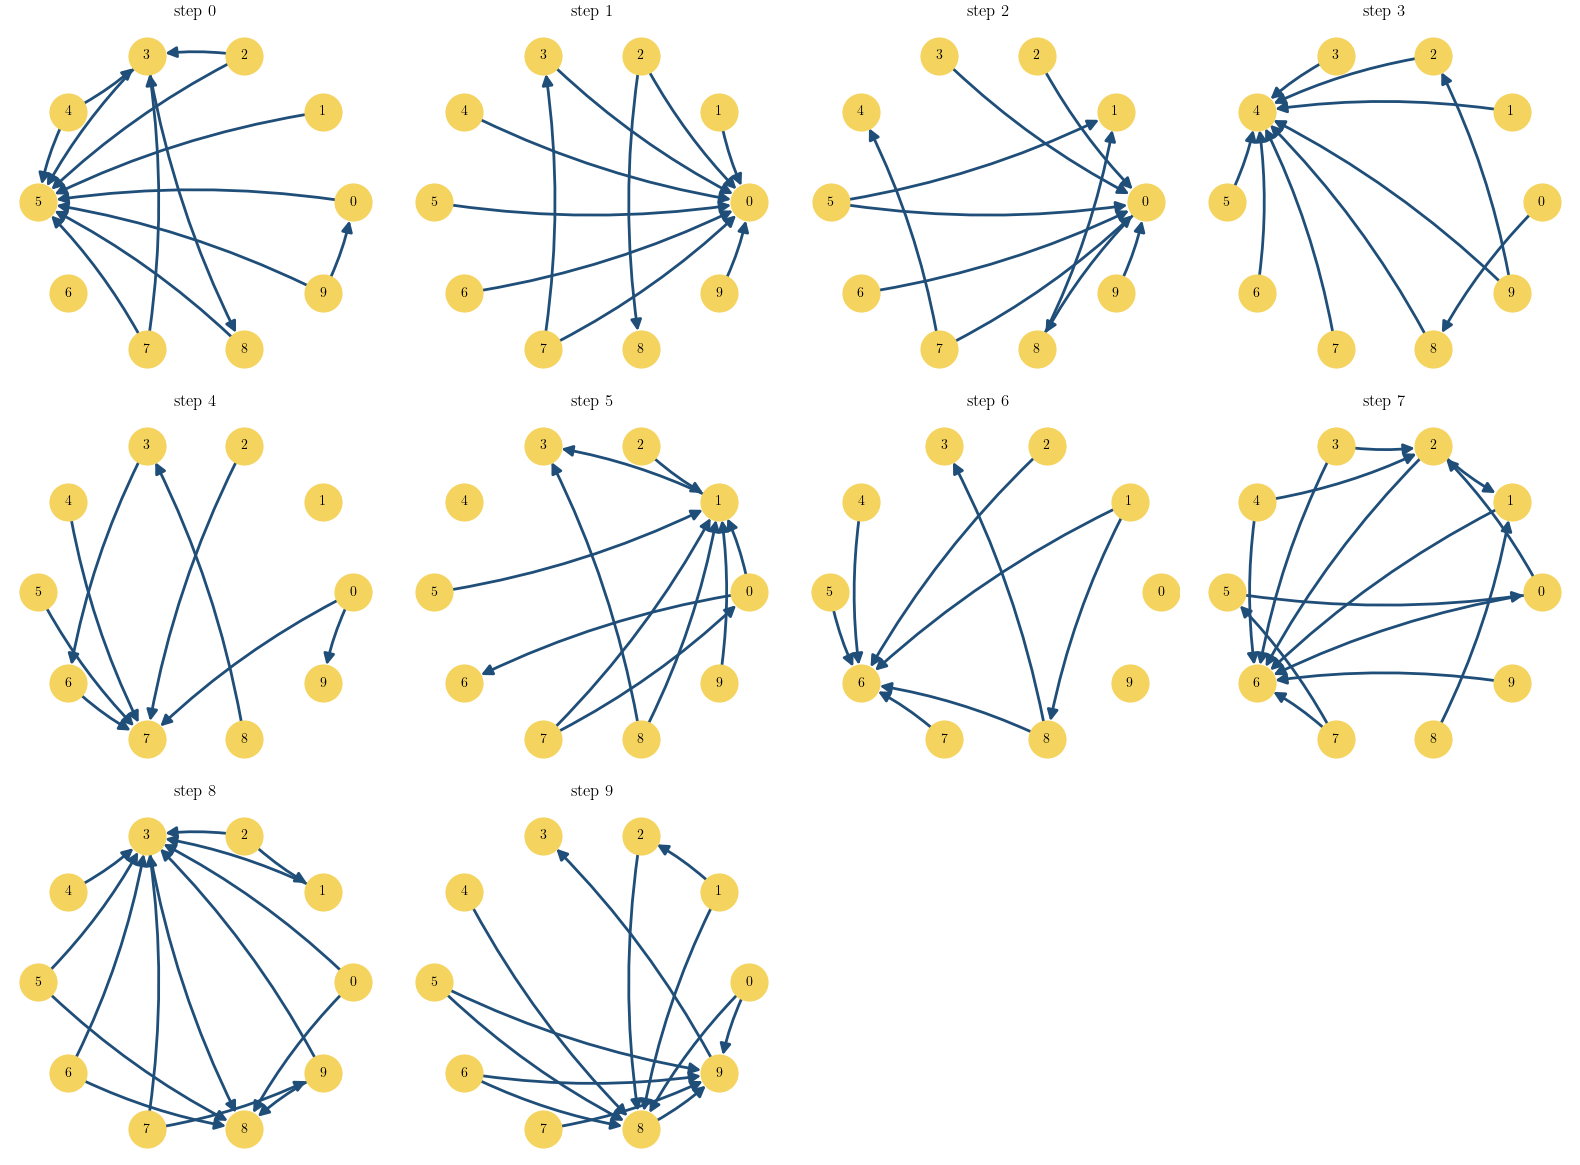

In [10]:
num_runs = 10
fixed_layout = build_circle_layout(n_nodes=n_agents)
plot_graph_history(
    steps=np.arange(num_runs),
    graphs=[graphs_run[-1] for graphs_run in state_history_observer._runs_graphs][:num_runs],
    layout=fixed_layout,
    figure_title="",
    max_cols=4,
)
plt.show()